# Step 1 General Description

In [3]:
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter
from sqlalchemy import and_, case, distinct, func, literal, or_

from epo.tipdata.patstat import PatstatClient
from epo.tipdata.patstat.database.models import (
    TLS201_APPLN,               # import the needed tables for the extractions
    TLS202_APPLN_TITLE,
    TLS203_APPLN_ABSTR,
    TLS206_PERSON,
    TLS207_PERS_APPLN,
    TLS224_APPLN_CPC,
    TLS230_APPLN_TECHN_FIELD,
    TLS901_TECHN_FIELD_IPC,
)

# Tables involved
## Core Patent Application Tables

* **`TLS201_APPLN` (Application Master Table)**
  * **Role:** The central spine of the entire PATSTAT database.
  * **Key attributes:** `appln_id` (the unique primary key used across PATSTAT), `appln_auth` (patent office code, e.g., US, EP, CN), `appln_nr`, `appln_filing_date`, `appln_filing_year`, `earliest_filing_year`, `docdb_family_id`, and `granted` flags.
  * **Usage:** Virtually every extraction joins onto `TLS201` to filter by application dates, countries, or patent family IDs.

* **`TLS202_APPLN_TITLE` (Application Titles)**
  * **Role:** Stores the titles of patent applications.
  * **Key attributes:** `appln_id`, `appln_title`, `appln_title_lg` (language of title).
  * **Usage:** Text analysis, keyword searching, or generating readable outputs.

* **`TLS203_APPLN_ABSTR` (Application Abstracts)**
  * **Role:** Stores patent abstracts and text summaries.
  * **Key attributes:** `appln_id`, `appln_abstract`, `appln_abstract_lg`.
  * **Usage:** NLP, topic modeling, and detailed keyword matching/classification.

---

## 3. Actors & Ownership Tables

* **`TLS206_PERSON` (Persons / Entities)**
  * **Role:** Master table of all unique applicants, inventors, and legal entities.
  * **Key attributes:** `person_id`, `person_name`, `person_address`, `person_ctry_code`, `doc_std_name` (standardized company/person name).
  * **Usage:** Identifying who owns the patent or who invented it, and tracing company portfolios.

* **`TLS207_PERS_APPLN` (Person-Application Relationship)**
  * **Role:** The many-to-many bridge table linking patents (`TLS201_APPLN`) to persons (`TLS206_PERSON`).
  * **Key attributes:** `appln_id`, `person_id`, `applt_seq_nr` (indicates if the person is an applicant / owner), `invt_seq_nr` (indicates if the person is an inventor).
  * **Usage:** Disentangling corporate assignees from individual inventors.

---

## 4. Classification & Technology Mapping Tables

* **`TLS224_APPLN_CPC` (Cooperative Patent Classification)**
  * **Role:** Contains the granular CPC classification codes assigned to each application.
  * **Key attributes:** `appln_id`, `cpc_class_symbol`, `cpc_scheme`, `cpc_version`.
  * **Usage:** Identifying precise technical domains (e.g., `Y02` for climate-mitigation technologies, `G06N` for AI/ML).

* **`TLS230_APPLN_TECHN_FIELD` (WIPO Technology Fields for Applications)**
  * **Role:** Pre-aggregated table mapping applications to the 35 WIPO technology fields (e.g., Computer Technology, Pharmaceuticals, Digital Communication).
  * **Key attributes:** `appln_id`, `techn_field_nr`, `weight`.
  * **Usage:** High-level industry and sectoral analysis without needing to manually map millions of IPC codes.

* **`TLS901_TECHN_FIELD_IPC` (Lookup / Concordance Table)**
  * **Role:** A reference concordance dictionary mapping IPC subclasses/groups to the 35 WIPO technology fields.
  * **Key attributes:** `ipc_maingroup_symbol`, `techn_field_nr`, `techn_sector`.
  * **Usage:** Translating specific IPC classification symbols into standardized broad technological sectors.

In [4]:
# ---------------------------------------------------------------- environment
ENV = "TEST"                 # develop on TEST, switch to "PROD" for the final numbers
OUTPUT_DIR = Path("outputs/step1") # name this how you wish

# ---------------------------------------------------------------- sector definition
SECTOR_NAME = "Surface Drones"
SECTOR_CPC_PREFIXES = (
    # Primary classification codes for Unmanned Surface Vessels (USVs)
    "B63B2035/006",  # Unmanned surface vessels, e.g. remotely controlled
    "B63B2035/007",  # Unmanned surface vessels, autonomously operating
    "B63B2035/008",  # Unmanned surface vessels, remotely controlled

    # Vessel Control, Navigation, and Autonomy
    "G05D1/00",      # Control of position, course, altitude or attitude of land, water, air, or space vehicles (Autopilot/Autonomous navigation)
    "G05D1/0206",    # Control of position or course of waterborne vessels
    "G08G3/00",      # Traffic control systems for marine craft

    # Waterborne craft adapted for special or military purposes
    "B63B35/00",     # Vessels or floating structures specially adapted for specific purposes
    "B63G8/001",     # Unmanned underwater or surface-supported craft systems / deployment
    "B63G13/00",     # Defense or military features adapted for waterborne vessels

    # Hybrid & amphibious drone operations (Air-Sea interactions)
    "B64U60/10",     # UAVs specially adapted for use on water (water-landing/amphibious drones)
    "B64U70/93"      # Launching/landing UAV platforms for use on nautical vehicles
)

# 1. Primary Vehicle Terminology
keywords_primary = [
    "unmanned surface vehicle",
    "USV",
    "unmanned surface vessel",
    "autonomous surface vehicle",
    "ASV",
    "autonomous surface vessel",
    "unmanned surface drone",
    "maritime drone",
    "marine drone",
    "aquatic drone",
    "waterborne drone",
    "remotely operated surface vessel",
    "crewless vessel",
    "uncrewed surface vessel",
    "robotic boat",
    "robotic vessel",
    "autonomous boat",
]

# 2. Form Factor & Design Terms
keywords_form_factor = [
    "surface craft",
    "surface vessel",
    "surface platform",
    "unmanned catamaran",
    "unmanned trimaran",
    "unmanned kayak",
    "semi-submersible surface vehicle",
    "autonomous hydrofoil",
    "wave glider",
    "saildrone",
]

# 3. Subsystem & Functional Keywords
keywords_subsystems = {
    "navigation_autonomy": [
        "obstacle avoidance",
        "path planning",
        "colregs compliance",
        "collision avoidance",
        "waypoint navigation",
        "autonomous docking",
        "dynamic positioning",
    ],
    "control_telemetry": [
        "teleoperation",
        "line-of-sight communication",
        "satellite communication",
        "SATCOM",
        "tethered control",
        "ground control station",
        "GCS",
    ],
    "propulsion_energy": [
        "hybrid propulsion",
        "electric outboard",
        "wave propulsion",
        "solar sails",
        "rigid sail",
        "waterjet propulsion",
        "thruster configuration",
    ],
    "payload_deployment": [
        "LARS",
        "launch and recovery system",
        "moon pool",
        "tether winch",
        "bathymetric sonar",
        "multibeam echosounder",
        "ROV deployment",
        "UAV landing pad",
    ],
}

SECTOR_KEYWORDS = (
    keywords_primary
    + keywords_form_factor
    + [kw for sublist in keywords_subsystems.values() for kw in sublist]
)

# ---------------------------------------------------------------- time window, you can choose and change!!
YEAR_MIN, YEAR_MAX = 2000, 2025

# Which year to use (see Section 3). Three columns of tls201_appln can date a patent:
#   "appln_filing_year"    year this application was filed
#   "earliest_publn_year"  year of the first publication
#   "earliest_filing_year" :
#   The earliest filing date in the **DOCDB family** of the application: the **priority date**. 
#   It is the same for all applications of the family, 
#   and it is the date closest to the moment of invention.

FAMILY_TIME_COLUMN = "earliest_filing_year"   # family level: the earliest one in the family (PW rule)
APPLN_TIME_COLUMN = "appln_filing_year"       # application level: the application's own filing year

# Last years that are still incomplete in PATSTAT, for each choice of year
TRUNCATED_YEARS = {"appln_filing_year": 3, 
                   "earliest_filing_year": 3, 
                   "earliest_publn_year": 1
                  }



# Publication vs Filing

The core difference between **filing** and **publication** lies in **who knows about the application** and **what legal milestones are triggered**.

---

### Comparison at a Glance

| Feature | Filing (`filing_date`) | Publication (`publn_date`) |
| --- | --- | --- |
| **What happens?** | You submit the application to the patent office. | The patent office makes the document accessible to the public. |
| **Visibility** | **Confidential / Secret** (only you and the patent office know). | **Public** (available in search engines, gazettes, PATSTAT). |
| **Timing** | Day 0 (establishes the **priority date**). | Usually **18 months** after the earliest filing/priority date. |
| **Legal Effect** | Establishes prior art cutoff and "first-to-file" priority rights. | Converts the invention into public prior art; creates provisional rights. |
| **Examination Status** | Formalities check; awaiting or undergoing examination. | Often published *before* substantive examination or grant decisions are finalized. |

---

### 1. Filing (`appln_filing_date`)

* **The Action:** The formal submission of a complete patent application (claims, description, drawings, fees) to a national or regional patent office (e.g., EPO, USPTO, WIPO).
* **Why it matters legally:**
* **First-to-File Priority:** It stamps an official timestamp. Anyone who invents or files the same concept *after* this moment cannot claim ownership over you.
* **Prior Art Cutoff:** Everything published *before* this date can be used to challenge your novelty/inventiveness; anything published *after* cannot invalidate your filing (under standard priority rules).


* **Status:** During this initial phase, the patent application is completely hidden from competitors and the public.

---

### 2. Publication (`earliest_publn_date`)

* **The Action:** The patent office publishes the bibliographic data, technical description, and claims in its official bulletin/database (e.g., Espacenet, USPTO Public PAIR, Google Patents).
* **The 18-Month Rule:** Under standard international patent practice (including the Paris Convention and PCT), patent offices keep the application sealed for **18 months** from the filing (or priority) date, after which it is mandatory to publish it—even if the patent has not yet been granted.
* **Why it matters legally:**
* **Becomes Prior Art:** From this day onward, your document is officially public prior art against everyone else in the world.
* **Provisional Rights:** In many jurisdictions, publication allows the applicant to claim provisional damages (reasonable royalties) against third parties who infringe on the claims between publication and final grant.
* **Competitor Awareness:** Competitors first learn what technologies you are developing and may file third-party observations or prepare oppositions.



---

### A Common Misconception: Publication vs. Grant

* **Publication $\neq$ Grant:** A published application is **not** an enforceable patent yet; it is merely an open application document (typically designated as an **A** publication, like `EP1234567A1`).
* **Grant:** When the patent office examines and actually approves the claims, it issues a **patent grant** (typically published as a **B** document, like `EP1234567B1`), which provides the full exclusive right to exclude others from practicing the invention.

# Patent Right-Truncation in PATSTAT Explained

```python
# Last years that are still incomplete in PATSTAT, for each choice of year
TRUNCATED_YEARS = {
    "appln_filing_year": 3,
    "earliest_filing_year": 3,
    "earliest_publn_year": 1
}

```

---

## 1. What Problem Is Highlighted Here?

The snippet highlights the **right-truncation problem** (systematic reporting and publication lag) inherent to patent databases like the EPO's PATSTAT.

When analyzing patent trends over time, patent counts for recent years artificially collapse—not because innovation or filing activity dropped, but because the applications have not yet been published or ingested into the database.

---

## 2. Why Truncation Occurs

### A. The 18-Month Secrecy Window (`appln_filing_year` & `earliest_filing_year`)

* **Legal Secrecy:** Under international patent rules (Paris Convention and PCT), patent applications remain strictly confidential for **18 months** from the priority date before publication.
* **Administrative & Snapshot Lag:** After publication by national patent offices (USPTO, EPO, JPO, etc.), it takes additional months for data to be exchanged, harmonized, and integrated into PATSTAT release snapshots (which typically occur twice a year: Spring and Autumn).
* **Net Delay:** In practice, complete coverage for a filing year is only achieved after roughly **2.5 to 3 years**.

### B. Ingestion Lag for Publications (`earliest_publn_year`)

* Publications do not suffer from the 18-month secrecy rule (they are published immediately upon reaching that date).
* However, there is still an administrative delivery and data extraction lag of several months up to **1 year** between the publication date at the issuing authority and its appearance in a specific PATSTAT release.
* **Net Delay:** Publication counts are generally incomplete for the most recent **1 year**.

---

## 3. Summary of Truncation Lags

| Date Field | Scope / Meaning | Lag / Cutoff | Primary Driver |
| --- | --- | --- | --- |
| `appln_filing_year` | Filing year of the application | **3 years** | 18-month secrecy window + office processing lag |
| `earliest_filing_year` | Priority filing year of the patent family | **3 years** | Same priority-to-publication cycle |
| `earliest_publn_year` | Year of earliest publication | **1 year** | Snapshot ingestion and data exchange delay |

---

## 4. Practical Implications for Empirical Analysis

Failing to remove or correct for truncated years leads to two common errors:

1. **Misleading Visualizations:** Plots of patent filings over time will show a steep, artificial drop at the tail end of the timeline, falsely suggesting a sudden collapse in R&D or technological output.
2. **Econometric Bias:** Time fixed effects, growth rate estimations, and cohort analyses will pick up database artifacts rather than true economic signals.

### Standard Filtering Pattern

```python
# Example: Truncation filtering applied to a PATSTAT extract
current_release_year = 2024  # Reference year of your PATSTAT snapshot

for date_col, lag in TRUNCATED_YEARS.items():
    if date_col in df.columns:
        valid_until_year = current_release_year - lag
        df = df[df[date_col] <= valid_until_year]

```

```

In [5]:
# ---------------------------------------------------------------- counting rules
IPR_TYPE = "PI"                                  # patents of invention only (excludes utility models "UM")
IP5_OFFICES = ("EP", "US", "CN", "JP", "KR")     # the five largest patent offices (Section 9)
TOP_N = 8                                        # categories shown in tables and figures; the rest is "Other"

# ---------------------------------------------------------------- derived

LAST_COMPLETE_YEAR = YEAR_MAX - max(TRUNCATED_YEARS[FAMILY_TIME_COLUMN], TRUNCATED_YEARS[APPLN_TIME_COLUMN])
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

patstat = PatstatClient(env=ENV)
db = patstat.orm()
print(f"Sector: {SECTOR_NAME} | env: {ENV} | years {YEAR_MIN}-{YEAR_MAX} "
      f"| family year: {FAMILY_TIME_COLUMN} | application year: {APPLN_TIME_COLUMN} "
      f"| complete years up to {LAST_COMPLETE_YEAR}")

Sector: Surface Drones | env: TEST | years 2000-2025 | family year: earliest_filing_year | application year: appln_filing_year | complete years up to 2022


## Selecting the sector

In [6]:
def symbol_prefix_condition(symbol_column, codes): 
    """OR-condition: the blank-stripped classification symbol starts with one of the codes."""
    symbol = func.replace(symbol_column, " ", "")
    return or_(*(symbol.like(code.replace(" ", "") + "%") for code in codes))

    # performs a search based on class-prefix matching:
    # Example: If SECTOR_CPC_PREFIXES = ["Y02E10", "H02S"], it matches any patent with a code starting 
    # with Y02E10 (e.g., Y02E10/50) or H02S.


def keyword_condition(terms):
    """OR-condition: any term appears in the title or abstract (case-insensitive)."""
    title = func.lower(TLS202_APPLN_TITLE.appln_title)
    abstract = func.lower(TLS203_APPLN_ABSTR.appln_abstract)
    return or_(*(col.like(f"%{t.lower()}%") for t in terms for col in (title, abstract)))

    # If any listed keyword appears in either the title or the abstract of 
    # an application, the condition evaluates to true.


def sector_family_ids(cpc_prefixes=SECTOR_CPC_PREFIXES, keywords=SECTOR_KEYWORDS):
    """Query of the docdb_family_ids that belong to the sector (CPC codes OR keywords)."""
    family_id = TLS201_APPLN.docdb_family_id.label("docdb_family_id")
    by_cpc = (
        db.query(family_id)
        .join(TLS224_APPLN_CPC, TLS201_APPLN.appln_id == TLS224_APPLN_CPC.appln_id)
        .filter(symbol_prefix_condition(TLS224_APPLN_CPC.cpc_class_symbol, cpc_prefixes))
    )
    if not keywords:
        return by_cpc.distinct()
    by_keywords = (
        db.query(family_id)
        .outerjoin(TLS202_APPLN_TITLE, TLS201_APPLN.appln_id == TLS202_APPLN_TITLE.appln_id)
        .outerjoin(TLS203_APPLN_ABSTR, TLS201_APPLN.appln_id == TLS203_APPLN_ABSTR.appln_id)
        .filter(keyword_condition(keywords))
    )
    return by_cpc.union(by_keywords)   # UNION removes duplicates

    


sector_ids = sector_family_ids()

# Single Most Globally Protected Patent Family

This snippet below identifies the **single most globally protected patent family within the previously selected sector**
and **extracts its complete filing history as a pandas DataFrame**.

In patent analytics, **family size (number of applications covering the same invention across jurisdictions) is a primary proxy for patent value** and **applicants only pay expensive national phase fees in multiple jurisdictions for their most critical assets.**

In [7]:
n_applications = func.count(TLS201_APPLN.appln_id)

largest_family = (
    db.query(TLS201_APPLN.docdb_family_id, n_applications.label("n_applications"))
    .filter(TLS201_APPLN.docdb_family_id.in_(sector_ids.subquery().select()))
    .group_by(TLS201_APPLN.docdb_family_id)
    .order_by(n_applications.desc())
    .limit(1)
)

example_family_id = int(patstat.df(largest_family).loc[0, "docdb_family_id"])

example_family = patstat.df(
    db.query(
        TLS201_APPLN.docdb_family_id,
        TLS201_APPLN.appln_id,
        TLS201_APPLN.appln_auth,
        TLS201_APPLN.appln_kind,
        TLS201_APPLN.appln_filing_date,
        TLS201_APPLN.appln_filing_year,
        TLS201_APPLN.earliest_publn_year,
        TLS201_APPLN.earliest_filing_year,
        TLS201_APPLN.granted,
        TLS201_APPLN.docdb_family_size,
    )
    .filter(TLS201_APPLN.docdb_family_id == example_family_id)
    .order_by(TLS201_APPLN.appln_filing_date)
)
example_family

,docdb_family_id,appln_id,appln_auth,appln_kind,appln_filing_date,appln_filing_year,earliest_publn_year,earliest_filing_year,granted,docdb_family_size
0,56849708,469051669,US,A,2016-03-04,2016,2016,2015,Y,58
1,56849708,469051106,US,A,2016-03-04,2016,2016,2015,Y,58
2,56849708,469053222,US,A,2016-03-04,2016,2016,2015,Y,58
3,56849708,469050822,US,A,2016-03-04,2016,2016,2015,Y,58
4,56849708,469051990,US,A,2016-03-04,2016,2016,2015,Y,58
5,56849708,469055248,US,A,2016-03-04,2016,2016,2015,Y,58
6,56849708,469050880,US,A,2016-03-04,2016,2016,2015,Y,58
7,56849708,469057402,US,A,2016-03-04,2016,2016,2015,Y,58
8,56849708,469058509,US,A,2016-03-04,2016,2016,2015,Y,58
9,56849708,469058269,US,A,2016-03-04,2016,2016,2015,Y,58


## Computing the True "Invention Birth Year" (family_year):

An invention's **true age in patent analytics is its earliest priority filing date**, not when later foreign applications or continuations were filed.

Taking the **minimum of earliest_filing_year nails down the exact year the inventor first staked a legal claim to the concept.**

In [8]:
years = example_family[["appln_id", "appln_auth", "appln_filing_year", "earliest_publn_year", "earliest_filing_year"]]


family_year = example_family["earliest_filing_year"].min()
print(f"Family {example_family_id}: {len(example_family)} applications filed between "
      f"{example_family['appln_filing_year'].min()} and {example_family['appln_filing_year'].max()}; "
      f"family year (earliest priority) = {family_year}")
years

Family 56849708: 37 applications filed between 2016 and 2021; family year (earliest priority) = 2015


,appln_id,appln_auth,appln_filing_year,earliest_publn_year,earliest_filing_year
0,469051669,US,2016,2016,2015
1,469051106,US,2016,2016,2015
2,469053222,US,2016,2016,2015
3,469050822,US,2016,2016,2015
4,469051990,US,2016,2016,2015
5,469055248,US,2016,2016,2015
6,469050880,US,2016,2016,2015
7,469057402,US,2016,2016,2015
8,469058509,US,2016,2016,2015
9,469058269,US,2016,2016,2015


## Scope

At its core, this code solves a classic dilemma in patent analysis:

> **Do you count the *inventions*, or do you count the *paperwork*?**

If a company invents one new battery and files patents for it in the US, Europe, China, and Japan, did they produce **1 innovation** or **4 patents**? 

Depending on your question, both answers are valid. This code sets up the data so you can look at both sides without writing your analysis code twice.

---

### The Problem: Why Patent Counting Gets Messy

Imagine two scenarios:
1. **Inventor A** invents a breakthrough solid-state battery. They file applications in 15 different countries.
2. **Inventor B** invents a minor screw tweak. They only file it in Italy.

* If you count **applications (the paperwork)**: Inventor A looks 15 times bigger than Inventor B.
* If you count **families (the inventions)**: Inventor A and Inventor B each count as exactly 1.

Furthermore, you often want to know: *“How is my sector (e.g., Green Hydrogen) doing compared to all technology worldwide?”*

To answer questions fairly, you need a **2 × 2 grid**:

| | **Sector Only** (e.g., Hydrogen) | **All Technology Worldwide** (The Baseline) |
|---|---|---|
| **Family Level** (Inventions) | How many hydrogen inventions exist? | How many inventions exist overall? |
| **Application Level** (Paperwork) | How many hydrogen filings were made? | How many filings were made overall? |

This snippet creates the exact database queries for those 4 boxes.

---

### How the Code Actually Works (Step by Step)

#### 1. Standardizing the Labels
Notice that both functions output the exact same 5 columns:
* `unit_id`: The ID of what is being counted (`docdb_family_id` or `appln_id`).
* `year`: The relevant year.
* `is_pct`: Is this related to an international patent (PCT)? (1 = Yes, 0 = No).
* `is_granted`: Did this get approved? (1 = Yes, 0 = No).
* `family_size`: How big is the patent family?

Because both levels output the **exact same column names**, any plotting function or calculation written later will work seamlessly on both.

---

#### 2. `family_scope()` — The "Invention" View
This collapses all applications belonging to the same invention into **one single row**:

* **What it groups by:** `docdb_family_id`.
* **Which year does it get?** `func.min(...)`. An invention is born the year the **very first priority application** was submitted. Later filings in other countries don't make the invention newer.
* **How are flags calculated?** It uses `func.max(...)`:
  * If the invention was granted in *at least one* country, `is_granted = 1`.
  * If it had *at least one* international PCT application, `is_pct = 1`.

---

#### 3. `application_scope()` — The "Paperwork" View
This does **no grouping**. Every single patent document gets its own row:

* **What it looks at:** Each individual `appln_id`.
* **Which year does it get?** The specific year *that specific office* received the application.
* **How are flags calculated?** Row-by-row:
  * Was *this specific office's filing* granted?
  * Is *this specific filing* a PCT application (`TLS201_APPLN.appln_auth == "WO"`)?

---

#### 4. `_restrict()` — Sector vs. Global Filter
This is a simple switch:
* If you pass `family_ids = sector_ids`, it keeps only the patents belonging to your chosen technology sector.
* If you pass `family_ids = None`, it leaves the filter off so you get every patent in the database (used to compute global baseline percentages).

---

#### 5. Packaging into `SCOPES`
The code packs the queries into a clean list of 4 objects:

```python
SCOPES = [
    Scope("all patents", "family", ...),       # 1. Global Inventions
    Scope(SECTOR_NAME,   "family", ...),       # 2. Sector Inventions
    Scope("all patents", "application", ...),  # 3. Global Paperwork
    Scope(SECTOR_NAME,   "application", ...),  # 4. Sector Paperwork
]

In [9]:
IS_PCT_APPLN = and_(TLS201_APPLN.appln_auth == "WO", TLS201_APPLN.appln_kind.like("W%"))
LEVELS = ("family", "application")
UNIT_LABEL = {"family": "families", "application": "applications"}


def _restrict(q, family_ids):
    """Keep only the families in family_ids (None = all patents)."""
    if family_ids is None:
        return q
    return q.filter(TLS201_APPLN.docdb_family_id.in_(family_ids.subquery().select()))


def family_scope(family_ids=None):
    """Family level: one row per DOCDB family."""
    year = func.min(getattr(TLS201_APPLN, FAMILY_TIME_COLUMN))
    q = db.query(
        TLS201_APPLN.docdb_family_id.label("unit_id"),
        year.label("year"),
        func.max(case((IS_PCT_APPLN, 1), else_=0)).label("is_pct"),
        func.max(case((TLS201_APPLN.granted == "Y", 1), else_=0)).label("is_granted"),
        func.max(TLS201_APPLN.docdb_family_size).label("family_size"),
    ).filter(TLS201_APPLN.ipr_type == IPR_TYPE)
    return (
        _restrict(q, family_ids)
        .group_by(TLS201_APPLN.docdb_family_id)
        .having(year.between(YEAR_MIN, YEAR_MAX))
        .subquery()
    )


def application_scope(family_ids=None, time_column=APPLN_TIME_COLUMN):
    """Application level: one row per appln_id, dated by its own time_column."""
    year = getattr(TLS201_APPLN, time_column)
    q = db.query(
        TLS201_APPLN.appln_id.label("unit_id"),
        year.label("year"),
        case((IS_PCT_APPLN, 1), else_=0).label("is_pct"),
        case((TLS201_APPLN.granted == "Y", 1), else_=0).label("is_granted"),
        TLS201_APPLN.docdb_family_size.label("family_size"),
    ).filter(TLS201_APPLN.ipr_type == IPR_TYPE, year.between(YEAR_MIN, YEAR_MAX))
    return _restrict(q, family_ids).subquery()


@dataclass(frozen=True)
class Scope:
    name: str     # "all patents" or the sector name
    level: str    # "family" or "application"
    sq: object    # SQLAlchemy subquery, one row per unit


SCOPES = [
    Scope("all patents", "family", family_scope()),
    Scope(SECTOR_NAME, "family", family_scope(sector_ids)),
    Scope("all patents", "application", application_scope()),
    Scope(SECTOR_NAME, "application", application_scope(sector_ids)),
]
SECTOR_SCOPES = [s for s in SCOPES if s.name == SECTOR_NAME]   # family first, then application

## Counting Functions

In [10]:
def _join_applications(q, scope):
    """Join the applications of each unit: all applications of a family, or the application itself."""
    key = TLS201_APPLN.docdb_family_id if scope.level == "family" else TLS201_APPLN.appln_id
    return q.join(TLS201_APPLN, key == scope.sq.c.unit_id).filter(TLS201_APPLN.ipr_type == IPR_TYPE)


def _tag(df, scope):
    return df.assign(scope=scope.name, level=scope.level)


def count_per_year(scope, only_pct=False):
    """Number of units (families or applications) per year; only_pct keeps those via PCT."""
    sq = scope.sq
    q = db.query(sq.c.year, func.count().label("n")).group_by(sq.c.year).order_by(sq.c.year)
    if only_pct:
        q = q.filter(sq.c.is_pct == 1)
    return _tag(patstat.df(q), scope)


def _split_equally(scope, unit_category, category):
    """Fractional counting: each unit is split equally across its distinct categories (sums to 1)."""
    pairs = unit_category.distinct().subquery()
    k = db.query(pairs.c.unit_id, func.count().label("k")).group_by(pairs.c.unit_id).subquery()
    q = (
        db.query(getattr(pairs.c, category), pairs.c.year, func.sum(1.0 / k.c.k).label("n_frac"))
        .join(k, k.c.unit_id == pairs.c.unit_id)
        .group_by(getattr(pairs.c, category), pairs.c.year)
    )
    return _tag(patstat.df(q), scope)


def fractional_by_country(scope, role="applicant"):
    """Fractional counts by person country and year (role: 'applicant' or 'inventor').

    Each unit is split among its distinct persons with a known country.
    """
    sq = scope.sq
    seq_nr = TLS207_PERS_APPLN.applt_seq_nr if role == "applicant" else TLS207_PERS_APPLN.invt_seq_nr
    ctry = func.trim(TLS206_PERSON.person_ctry_code)   # unknown countries are NULL, '' or blanks ('  ')
    persons = (
        _join_applications(
            db.query(sq.c.unit_id, sq.c.year, TLS207_PERS_APPLN.person_id, ctry.label("ctry")).distinct(), scope
        )
        .join(TLS207_PERS_APPLN, TLS207_PERS_APPLN.appln_id == TLS201_APPLN.appln_id)
        .join(TLS206_PERSON, TLS206_PERSON.person_id == TLS207_PERS_APPLN.person_id)
        .filter(seq_nr > 0, ctry.isnot(None), ctry != "")
        .subquery()
    )
    # one person = one share of the unit; a country with 2 of 3 persons gets 2/3
    k = db.query(persons.c.unit_id, func.count().label("k")).group_by(persons.c.unit_id).subquery()
    q = (
        db.query(persons.c.ctry, persons.c.year, func.sum(1.0 / k.c.k).label("n_frac"))
        .join(k, k.c.unit_id == persons.c.unit_id)
        .group_by(persons.c.ctry, persons.c.year)
    )
    return _tag(patstat.df(q), scope).assign(role=role)


def fractional_by_cpc_subclass(scope):
    """Fractional counts by CPC subclass (first 4 characters) and year."""
    sq = scope.sq
    subclass = func.substr(func.replace(TLS224_APPLN_CPC.cpc_class_symbol, " ", ""), 1, 4)
    q = (
        _join_applications(db.query(sq.c.unit_id, sq.c.year, subclass.label("subclass")), scope)
        .join(TLS224_APPLN_CPC, TLS224_APPLN_CPC.appln_id == TLS201_APPLN.appln_id)
    )
    return _split_equally(scope, q, "subclass")


def fractional_by_techn_field(scope):
    """Fractional counts by WIPO technology field (1-35) and year.

    tls230 weights sum to 1 per application; at family level they are rescaled
    so that every family also sums to 1.
    """
    sq = scope.sq
    unit_field = (
        _join_applications(
            db.query(sq.c.unit_id, sq.c.year, TLS230_APPLN_TECHN_FIELD.techn_field_nr,
                     func.sum(TLS230_APPLN_TECHN_FIELD.weight).label("w")),
            scope,
        )
        .join(TLS230_APPLN_TECHN_FIELD, TLS230_APPLN_TECHN_FIELD.appln_id == TLS201_APPLN.appln_id)
        .group_by(sq.c.unit_id, sq.c.year, TLS230_APPLN_TECHN_FIELD.techn_field_nr)
        .subquery()
    )
    unit_total = (
        db.query(unit_field.c.unit_id, func.sum(unit_field.c.w).label("w_total"))
        .group_by(unit_field.c.unit_id)
        .subquery()
    )
    q = (
        db.query(unit_field.c.techn_field_nr, unit_field.c.year,
                 func.sum(unit_field.c.w / unit_total.c.w_total).label("n_frac"))
        .join(unit_total, unit_total.c.unit_id == unit_field.c.unit_id)
        .group_by(unit_field.c.techn_field_nr, unit_field.c.year)
    )
    return _tag(patstat.df(q), scope)


def count_by_office(scope):
    """Units per office and year.

    Family level: families with at least one application at the office.
    Application level: applications filed at the office.
    """
    sq = scope.sq
    q = (
        _join_applications(
            db.query(TLS201_APPLN.appln_auth.label("office"), sq.c.year,
                     func.count(distinct(sq.c.unit_id)).label("n")),
            scope,
        )
        .group_by(TLS201_APPLN.appln_auth, sq.c.year)
    )
    return _tag(patstat.df(q), scope)


def scope_profile(scope):
    """Number of units, units via PCT, granted units and mean family size (complete years only)."""
    sq = scope.sq
    q = db.query(
        func.count().label("n"),
        func.sum(sq.c.is_pct).label("n_pct"),
        func.sum(sq.c.is_granted).label("n_granted"),
        func.avg(sq.c.family_size * 1.0).label("mean_family_size"),
    ).filter(sq.c.year <= LAST_COMPLETE_YEAR)
    return _tag(patstat.df(q), scope)

## Analysis helpers (pandas)

In [11]:
def shade_truncated(ax):
    """Shade the incomplete (truncated) years on a time axis."""
    ax.axvspan(LAST_COMPLETE_YEAR + 0.5, YEAR_MAX + 0.5, color="grey", alpha=0.15, lw=0,
               label="incomplete years")


def complete_years(df):
    return df[df["year"] <= LAST_COMPLETE_YEAR]


def pool_other(df, category, n=TOP_N, value="n_frac", other_label="Other"):
    """Keep the n largest categories (over the complete years) and pool the rest into 'Other'."""
    top = complete_years(df).groupby(category)[value].sum().nlargest(n).index
    out = df.copy()
    out[category] = out[category].where(out[category].isin(top), other_label)
    return out.groupby([category, "year"], as_index=False)[value].sum()


def share_table(counts):
    """Counts -> percentages that sum to 100 in every column, with 'Other' last and a 'Total' row."""
    shares = counts / counts.sum() * 100
    order = [c for c in shares.sort_values(shares.columns[0], ascending=False).index if c != "Other"]
    order += ["Other"] if "Other" in shares.index else []
    shares = shares.loc[order]
    shares.loc["Total"] = shares.sum()
    return shares


def share_over_time(df, category, value="n_frac"):
    """Year x category table of percentages (each year sums to 100)."""
    wide = df.pivot_table(index="year", columns=category, values=value, aggfunc="sum", fill_value=0)
    wide = wide.div(wide.sum(axis=1), axis=0) * 100
    order = [c for c in complete_years(wide.reset_index()).set_index("year").sum().sort_values(ascending=False).index
             if c != "Other"]
    return wide[order + (["Other"] if "Other" in wide.columns else [])]


def stack_100(ax, shares, title):
    """Stacked area of percentages, y axis from 0% to 100%."""
    palette = [c for i, c in enumerate(plt.get_cmap("tab10").colors) if i != 7]   # no grey: grey = "Other"
    colors = ["lightgrey" if c == "Other" else palette[i % len(palette)] for i, c in enumerate(shares.columns)]
    ax.stackplot(shares.index, shares.T.values, labels=shares.columns, colors=colors, alpha=0.85)
    shade_truncated(ax)
    ax.set(title=title, xlabel="year", xlim=(YEAR_MIN, YEAR_MAX), ylim=(0, 100))
    ax.yaxis.set_major_formatter(PercentFormatter(100))


def pct_format(df):
    return df.style.format("{:.1f}%")


def side_by_side(title, **kw):
    """Two axes: families (left) and applications (right)."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), **kw)
    fig.suptitle(title)
    return fig, axes

## Volume: how big is the sector

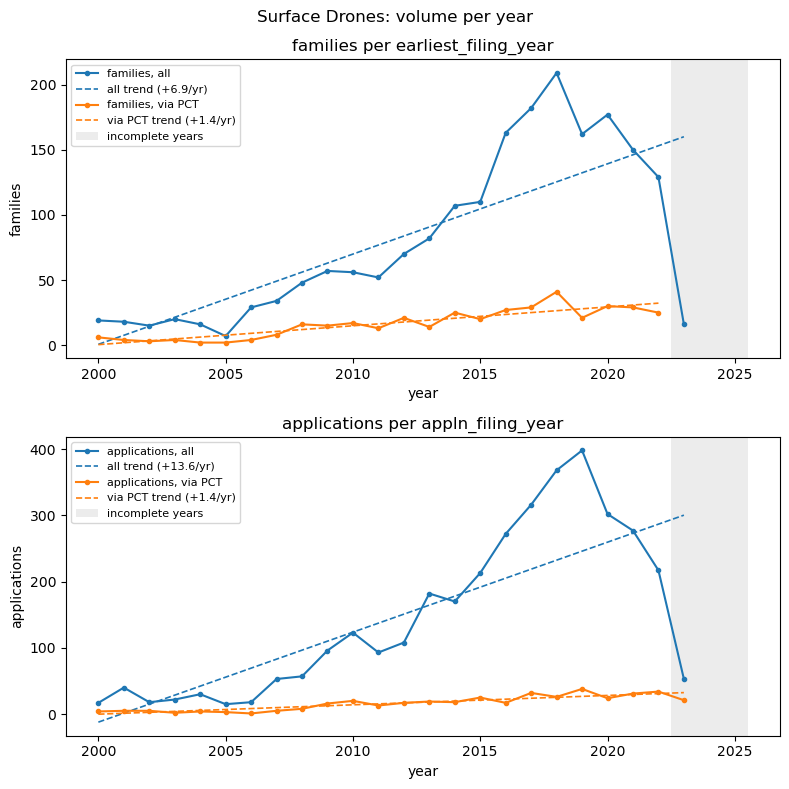

In [12]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

volume = pd.concat(
    [count_per_year(s).assign(series="all") for s in SCOPES]
    + [count_per_year(s, only_pct=True).assign(series="via PCT") for s in SCOPES],
    ignore_index=True,
)

volume["year"] = pd.to_numeric(volume["year"])
volume["n"] = pd.to_numeric(volume["n"])

n_plots = len(SECTOR_SCOPES)
fig, axes = plt.subplots(
    nrows=n_plots,
    ncols=1,
    sharex=True,
    figsize=(8, 4 * n_plots),
)

if n_plots == 1:
    axes = [axes]

fig.suptitle(f"{SECTOR_NAME}: volume per year")

for ax, scope in zip(axes, SECTOR_SCOPES):
    data = volume.query("scope == @scope.name and level == @scope.level")
    
    for series, grp in data.groupby("series"):
        grp = grp.sort_values("year")
        
        # Plot raw series line
        line, = ax.plot(
            grp["year"],
            grp["n"],
            marker="o",
            ms=3,
            label=f"{UNIT_LABEL[scope.level]}, {series}",
        )
        
        # Fit linear regression (excluding NaN values)
        valid = grp.dropna(subset=["year", "n"])
        if len(valid) > 1:
            slope, intercept = np.polyfit(valid["year"], valid["n"], deg=1)
            y_pred = slope * valid["year"] + intercept
            
            # Plot regression line matching the series color
            ax.plot(
                valid["year"],
                y_pred,
                linestyle="--",
                linewidth=1.2,
                color=line.get_color(),
                label=f"{series} trend ({slope:+.1f}/yr)",
            )

    shade_truncated(ax)
    year_col = FAMILY_TIME_COLUMN if scope.level == "family" else APPLN_TIME_COLUMN
    ax.set(
        title=f"{UNIT_LABEL[scope.level]} per {year_col}",
        xlabel="year",
        ylabel=UNIT_LABEL[scope.level],
    )
    ax.ticklabel_format(style="plain", axis="y", useOffset=False)
    ax.tick_params(labelbottom=True)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig("surface_drones_volumes.png", format="png")
plt.show()

In [13]:
bgn=2000
end=2022

In [14]:
volume_df = volume[((volume['year']==bgn) | (volume['year']==end))]
volume_df

,year,n,scope,level,series
0,2000,2092,all patents,family,all
22,2022,10902,all patents,family,all
24,2000,19,Surface Drones,family,all
46,2022,129,Surface Drones,family,all
48,2000,1957,all patents,application,all
70,2022,14162,all patents,application,all
73,2000,17,Surface Drones,application,all
95,2022,217,Surface Drones,application,all
97,2000,165,all patents,family,via PCT
119,2022,876,all patents,family,via PCT


In [15]:
pivot_df = pd.pivot_table(data=volume_df[volume_df['level']=='family'], values='n', index=['scope'],columns=['year','series'])
pivot_df

year              2000             2022        
series             all via PCT      all via PCT
scope                                          
Surface Drones    19.0     6.0    129.0    25.0
all patents     2092.0   165.0  10902.0   876.0

In [16]:
sd_growth = (pivot_df[2022].iloc[0]-pivot_df[2000].iloc[0])/pivot_df[2000].iloc[0]*100
print(f"surface drones' growth 2000-2022: \n {sd_growth}")
ap_growth = (pivot_df[2022].iloc[1]-pivot_df[2000].iloc[1])/pivot_df[2000].iloc[1]*100
print(f"all patents' growth 2000-2022: \n {ap_growth}")

surface drones' growth 2000-2022: 
 series
all        578.947368
via PCT    316.666667
Name: Surface Drones, dtype: float64
all patents' growth 2000-2022: 
 series
all        421.128107
via PCT    430.909091
Name: all patents, dtype: float64


## Same sector, three ways to date it

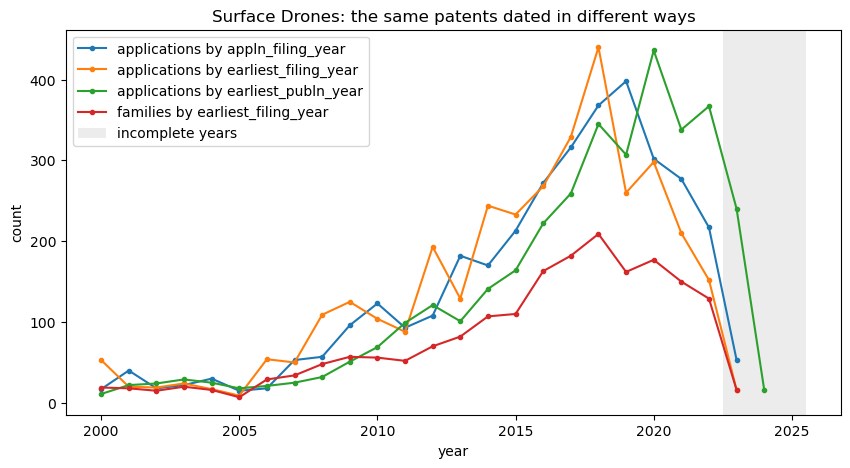

In [17]:
dating = pd.concat(
    [
        count_per_year(Scope(SECTOR_NAME, "application", application_scope(sector_ids, col)))
        .assign(series=f"applications by {col}")
        for col in ("appln_filing_year", "earliest_publn_year", "earliest_filing_year")
    ]
    + [volume.query("scope == @SECTOR_NAME and level == 'family' and series == 'all'")
       .assign(series=f"families by {FAMILY_TIME_COLUMN}")],
    ignore_index=True,
)

fig, ax = plt.subplots(figsize=(10, 5))
for series, grp in dating.groupby("series"):
    ax.plot(grp["year"], grp["n"], marker="o", ms=3, label=series)
shade_truncated(ax)
ax.set(title=f"{SECTOR_NAME}: the same patents dated in different ways", xlabel="year", ylabel="count")
ax.legend()
plt.show()

## Growth: is the sector growing faster than patenting as a whole?

In [18]:
start, end = YEAR_MIN, LAST_COMPLETE_YEAR
totals = volume.query("series == 'all'").pivot_table(index="year", columns=["level", "scope"], values="n")

growth = pd.DataFrame({
    f"count in {start}": totals.loc[start],
    f"count in {end}": totals.loc[end],
    f"growth {start}-{end} (%)": (totals.loc[end] / totals.loc[start] - 1) * 100,
}).loc[[(lvl, s) for lvl in LEVELS for s in ("all patents", SECTOR_NAME)]]

growth.style.format({f"count in {start}": "{:,.0f}", f"count in {end}": "{:,.0f}",
                     f"growth {start}-{end} (%)": "{:+.1f}%"})

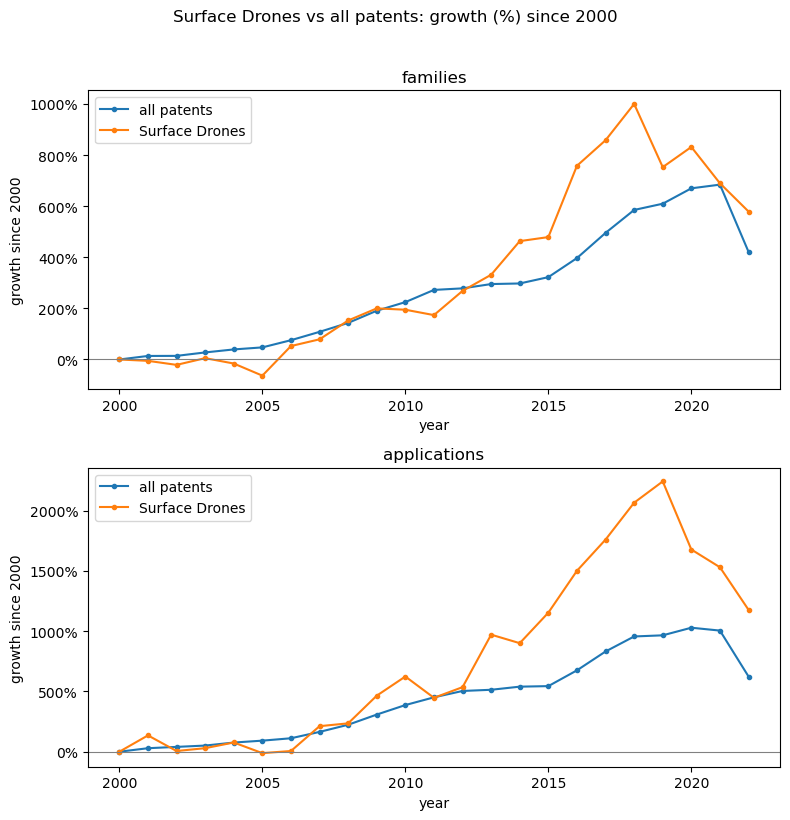

In [19]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

growth_path = (totals.loc[start:end] / totals.loc[start] - 1) * 100

fig, axes = plt.subplots(
    nrows=len(LEVELS), 
    ncols=1, 
    figsize=(8, 4 * len(LEVELS)), 
    sharex=True
)

if len(LEVELS) == 1:
    axes = [axes]

fig.suptitle(f"{SECTOR_NAME} vs all patents: growth (%) since {start}", y=1.02)

for ax, level in zip(axes, LEVELS):
    for scope_name in ("all patents", SECTOR_NAME):
        ax.plot(
            growth_path.index, 
            growth_path[(level, scope_name)], 
            marker="o", 
            ms=3, 
            label=scope_name
        )
    ax.axhline(0, color="grey", lw=0.8)
    ax.set(title=UNIT_LABEL[level], xlabel="year", ylabel=f"growth since {start}")
    ax.yaxis.set_major_formatter(PercentFormatter(100))
    ax.legend()
    
    # Force tick marks and labels visible on this axis
    ax.tick_params(labelbottom=True)

plt.tight_layout()
plt.savefig('surface_drones_patents_growth.png', format='png', bbox_inches='tight')
plt.show()

In [20]:
print(f"growth in percentage from year 2000: \n {growth_path['family'].loc[[2022]]}")

growth in percentage from year 2000: 
 scope  Surface Drones  all patents
year                              
2022       578.947368   421.128107


## Technology Mix: 

Which subclasses dominate the sector, and how is the mix shifting? Each family (or application) is split equally across its CPC subclasses, so the shares sum to 100%. Many subclasses are co-classifications: a wave energy family is often also classified in, for example, power generation or ships. They show which neighbouring technologies the sector draws on.

In [23]:
cpc_mix = pd.concat([fractional_by_cpc_subclass(s) for s in SECTOR_SCOPES], ignore_index=True)
cpc_pooled = pd.concat([pool_other(cpc_mix[cpc_mix["level"] == lvl], "subclass").assign(level=lvl)
                        for lvl in LEVELS], ignore_index=True)

cpc_counts = complete_years(cpc_pooled).pivot_table(index="subclass", columns="level", values="n_frac",
                                                    aggfunc="sum", fill_value=0)[list(LEVELS)]
cpc_shares = share_table(cpc_counts)
cpc_shares["definition"] = ""   # deck table: add the official titles
cpc_shares.style.format("{:.1f}%", subset=list(LEVELS))

level,family,application,definition
subclass,,,
B63B,15.7%,13.6%,
Y02E,11.3%,14.1%,
G05D,7.7%,5.4%,
F03D,6.8%,10.4%,
F05B,3.9%,7.0%,
E02B,3.4%,4.2%,
B64C,2.8%,2.3%,
B64U,2.6%,2.2%,
Other,45.9%,40.7%,


In [153]:
!wget https://www.cooperativepatentclassification.org/sites/default/files/cpc/bulk/CPCSchemeXML202608.zip

--2026-11-01 14:35:18--  https://www.cooperativepatentclassification.org/sites/default/files/cpc/bulk/CPCSchemeXML202608.zip
Resolving www.cooperativepatentclassification.org (www.cooperativepatentclassification.org)... 141.101.90.107, 141.101.90.104, 141.101.90.106, ...
Connecting to www.cooperativepatentclassification.org (www.cooperativepatentclassification.org)|141.101.90.107|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 9916671 (9.5M) [application/zip]
Saving to: ‘CPCSchemeXML202608.zip’

CPCSchemeXML202608. 100%[===================>]   9.46M  --.-KB/s    in 0.1s    

2026-11-01 14:35:19 (97.4 MB/s) - ‘CPCSchemeXML202608.zip’ saved [9916671/9916671]



In [28]:
import xml.etree.ElementTree as ET
import zipfile
import pandas as pd


def cpc_zip_to_dataframe(zip_path: str) -> pd.DataFrame:
    records = []

    with zipfile.ZipFile(zip_path, "r") as z:
        # Filter for all scheme XML files
        xml_names = [
            f
            for f in z.namelist()
            if f.endswith(".xml") and "cpc-scheme-" in f
        ]

        for name in xml_names:
            with z.open(name) as f:
                tree = ET.parse(f)
                root = tree.getroot()

                for item in root.iter("classification-item"):
                    symbol_elem = item.find("classification-symbol")
                    title_elem = item.find("class-title")

                    if symbol_elem is not None and symbol_elem.text:
                        symbol = symbol_elem.text.strip()
                        title = (
                            " ".join(
                                "".join(title_elem.itertext()).split()
                            ).strip()
                            if title_elem is not None
                            else ""
                        )
                        records.append({"cpc_symbol": symbol, "title": title})

    return pd.DataFrame(records).drop_duplicates(subset=["cpc_symbol"])

In [29]:
df_cpc_titles = cpc_zip_to_dataframe("CPCSchemeXML202608.zip")

In [30]:
df_cpc_titles

,cpc_symbol,title
0,A,HUMAN NECESSITIES
1,A01,AGRICULTURE
3,A01B,"SOIL WORKING IN AGRICULTURE OR FORESTRYPARTS, ..."
4,A01C,"PLANTINGSOWINGFERTILISING parts, details or ac..."
5,A01D,HARVESTINGMOWING
...,...,...
256831,Y10T483/1864,including tool pot or adapter
256832,Y10T483/1873,Indexing matrix
256833,Y10T483/1882,Rotary disc
256834,Y10T483/1891,Chain or belt


In [31]:
# Create a quick lookup dictionary (stripping whitespace to prevent mismatch)
title_map = dict(
    zip(
        df_cpc_titles["cpc_symbol"].str.strip(),
        df_cpc_titles["title"].str.strip(),
    )
)

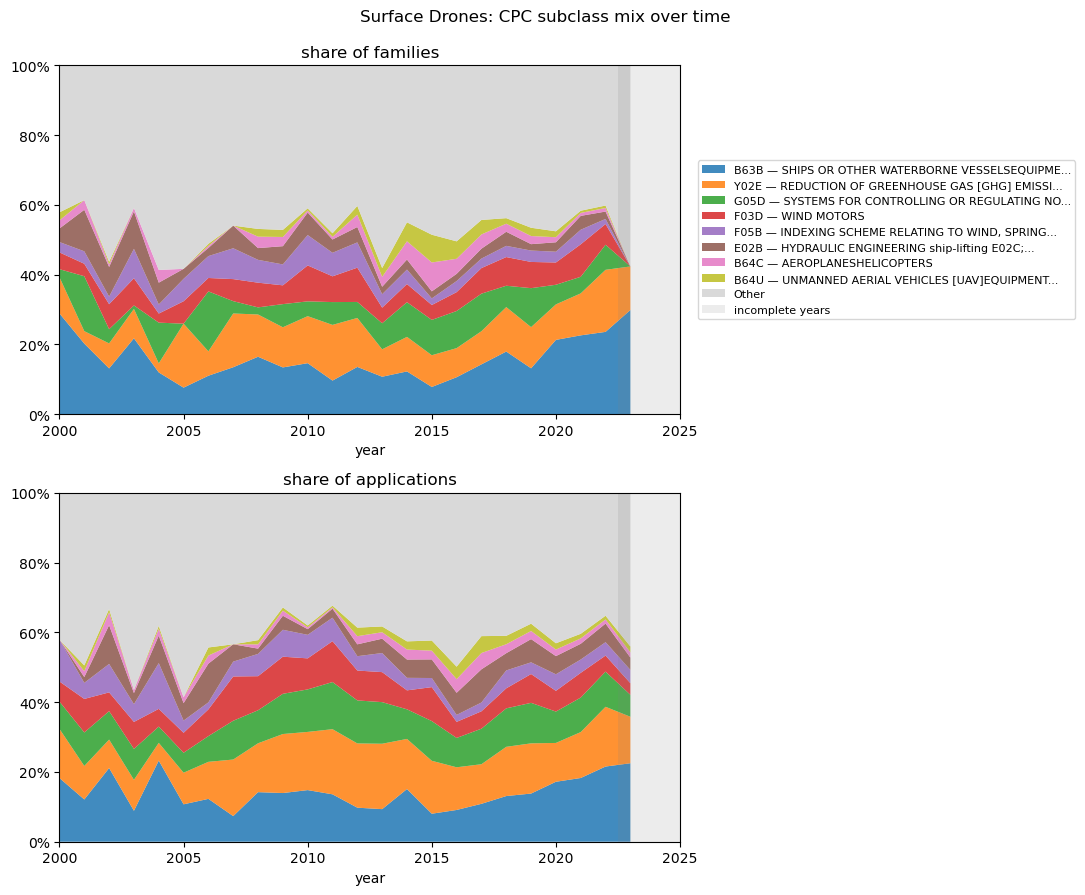

In [34]:
'''
fig, axes = side_by_side(f"{SECTOR_NAME}: CPC subclass mix over time", sharey=True)
for ax, level in zip(axes, LEVELS):
    stack_100(ax, share_over_time(cpc_pooled[cpc_pooled["level"] == level], "subclass"),
              f"share of {UNIT_LABEL[level]}")
axes[-1].legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=8)
plt.tight_layout()
plt.show()

'''
import matplotlib.pyplot as plt

MAX_CHARS = 40  # Set your maximum character threshold for the definition

# Create vertical layout: one column, stacked rows
fig, axes = plt.subplots(
    nrows=len(LEVELS),
    ncols=1,
    figsize=(11, 4.5 * len(LEVELS)),
    sharex=True,
)

# Ensure axes is iterable if LEVELS has only 1 element
if len(LEVELS) == 1:
    axes = [axes]

fig.suptitle(f"{SECTOR_NAME}: CPC subclass mix over time", y=0.99)


def format_cpc_label(code, max_len=MAX_CHARS):
    title = title_map.get(code)
    if not title:
        return code
    truncated_title = (
        title[:max_len].rstrip() + "..." if len(title) > max_len else title
    )
    return f"{code} — {truncated_title}"


for ax, level in zip(axes, LEVELS):
    shares = share_over_time(
        cpc_pooled[cpc_pooled["level"] == level], "subclass"
    )
    stack_100(ax, shares, f"share of {UNIT_LABEL[level]}")

    # Ensure x-axis ticks and labels show on all subplots
    ax.tick_params(labelbottom=True)
    ax.set_xlabel("year")

# Place a single legend alongside the first subplot
handles, labels = axes[0].get_legend_handles_labels()
formatted_labels = [format_cpc_label(c) for c in labels]

axes[0].legend(
    handles,
    formatted_labels,
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    fontsize=8,
    frameon=True,
)

plt.tight_layout()
plt.savefig("technology_mix.png", format="png", bbox_inches="tight")
plt.show()

In [54]:
cpc_shares

level,family,application,definition
subclass,,,
B63B,15.716437,13.608047,SHIPS OR OTHER WATERBORNE VESSELSEQUIPMENT FOR...
Y02E,11.266784,14.119289,"REDUCTION OF GREENHOUSE GAS [GHG] EMISSIONS, R..."
G05D,7.714000,5.398027,SYSTEMS FOR CONTROLLING OR REGULATING NON-ELEC...
F03D,6.807023,10.392402,WIND MOTORS
F05B,3.887753,7.042208,"INDEXING SCHEME RELATING TO WIND, SPRING, WEIG..."
E02B,3.369052,4.228538,HYDRAULIC ENGINEERING ship-lifting E02C; dredg...
B64C,2.760639,2.306941,AEROPLANESHELICOPTERS
B64U,2.567906,2.163818,UNMANNED AERIAL VEHICLES [UAV]EQUIPMENT THEREFOR
Other,45.910406,40.740731,


In [63]:
import re
import dataframe_image as dfi


def clean_cpc_title(title, max_len=45):
    """Pulisce il titolo CPC rimuovendo riferimenti ed esclusioni e tronca alla lunghezza indicata."""
    if not title:
        return ""
    # 1. Rimuove rimandi o codici tra parentesi, es: (ship-lifting E02C; ...)
    cleaned = re.sub(r"\(.*?\)", "", title)

    # 2. Rimuove eventuali sezioni di esclusione introdotte da punto e virgola o codici residui
    cleaned = re.split(r"[;]|\b[A-H]\d{2}[A-Z]\b", cleaned)[0]
    cleaned = cleaned.strip(" ;,-")

    # 3. Tronca alla lunghezza massima impostata aggiungendo i puntini di sospensione se necessario
    return (
        cleaned[:max_len].rstrip() + "..."
        if len(cleaned) > max_len
        else cleaned
    )


# 1. Applica la pulizia alla colonna delle definizioni
cpc_shares["definition"] = [
    clean_cpc_title(title_map.get(idx, ""), max_len=45)
    for idx in cpc_shares.index
]

# 2. Formatta le colonne numeriche come percentuali a un decimale
styled_table = cpc_shares.style.format("{:.1f}%", subset=list(LEVELS))

In [49]:
!pip install dataframe_image

In [64]:
#  Salva la tabella formattata in PNG tramite dfi
dfi.export(styled_table, "cpc_shares_table.png",table_conversion="matplotlib", dpi=300)

## WIPO technology fields

WIPO groups all patents into 35 technology fields, which belong to 5 technology sectors: Electrical engineering, Instruments, Chemistry, Mechanical engineering, Other fields (tables tls230 + tls901). It is a coarser view than CPC, the same for every country and every sector.

The question is simple: of 100 sector families, how many are in each technology sector? For example, 
"15% of wave energy families are in Instruments and 80% in Mechanical engineering". 
    
The shares sum to 100%.

In [35]:
field_names = patstat.df(
    db.query(TLS901_TECHN_FIELD_IPC.techn_field_nr, TLS901_TECHN_FIELD_IPC.techn_field,
             TLS901_TECHN_FIELD_IPC.techn_sector).distinct()
).drop_duplicates("techn_field_nr")

fields = (
    pd.concat([fractional_by_techn_field(s) for s in SECTOR_SCOPES], ignore_index=True)
    .merge(field_names, on="techn_field_nr", how="left")
)

techn_sector_counts = complete_years(fields).pivot_table(index="techn_sector", columns="level", values="n_frac",
                                                         aggfunc="sum", fill_value=0)[list(LEVELS)]
techn_sector_shares = share_table(techn_sector_counts)
pct_format(techn_sector_shares)

level,family,application
techn_sector,,
Mechanical engineering,59.7%,63.1%
Instruments,16.8%,13.6%
Electrical engineering,12.7%,12.1%
Other fields,9.4%,10.1%
Chemistry,1.4%,1.1%
Total,100.0%,100.0%


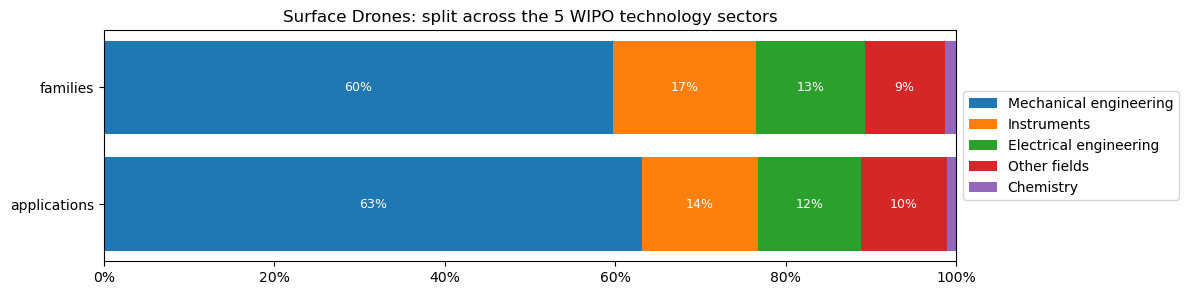

In [36]:
# One bar per level, split into the 5 technology sectors (each bar = 100%)
bars = techn_sector_shares.drop("Total").T

fig, ax = plt.subplots(figsize=(11, 3))
left = np.zeros(len(bars))
for techn_sector in bars.columns:
    values = bars[techn_sector].values
    ax.barh([UNIT_LABEL[l] for l in bars.index], values, left=left, label=techn_sector)
    for y, (x0, v) in enumerate(zip(left, values)):
        if v >= 5:
            ax.text(x0 + v / 2, y, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=9)
    left += values
ax.set(title=f"{SECTOR_NAME}: split across the 5 WIPO technology sectors", xlim=(0, 100))
ax.xaxis.set_major_formatter(PercentFormatter(100))
ax.invert_yaxis()
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.show()

The same split at the finer level of the 35 fields (largest fields, the rest in Other):

In [37]:
field_counts = complete_years(fields).pivot_table(index="techn_field", columns="level", values="n_frac",
                                                  aggfunc="sum", fill_value=0)[list(LEVELS)]
top_fields = field_counts["family"].nlargest(TOP_N).index
field_counts = field_counts.groupby(field_counts.index.where(field_counts.index.isin(top_fields), "Other")).sum()
pct_format(share_table(field_counts))

level,family,application
techn_field,,
Transport,35.8%,32.7%
"Engines, pumps, turbines",16.1%,22.8%
Control,10.3%,7.7%
Civil engineering,8.9%,9.7%
Measurement,5.9%,5.4%
"Electrical machinery, apparatus, energy",4.8%,6.0%
Computer technology,3.7%,2.9%
Handling,3.4%,3.6%
Other,11.2%,9.1%


## Geography of patents

Where do applicants seek protection? 
Offices with many sector filings are the markets that applicants consider worth protecting.

Application level: each application is filed at exactly one office, so we can split the sector's applications across offices and the shares sum to 100% (IP5, WO for PCT applications, and Other offices).


Family level: one family is usually filed at several offices, so the office counts of a family overlap and do not sum to the number of families. We therefore show counts, not shares: "how many inventions are protected at each office".

In [38]:
offices = pd.concat([count_by_office(s) for s in SECTOR_SCOPES], ignore_index=True)
offices["office"] = offices["office"].where(offices["office"].isin(IP5_OFFICES + ("WO",)), "Other")
offices = offices.groupby(["level", "office", "year"], as_index=False)["n"].sum()

# Application level: shares across offices (sum to 100%)
office_counts = complete_years(offices.query("level == 'application'")).groupby("office")["n"].sum().to_frame("applications")
office_shares = share_table(office_counts)
print(f"Share of the sector's applications filed at the IP5: {office_shares.loc[list(IP5_OFFICES), 'applications'].sum():.1f}%")
pct_format(office_shares)

Share of the sector's applications filed at the IP5: 70.4%


,applications
office,
US,28.3%
CN,23.4%
WO,10.8%
EP,8.7%
KR,6.8%
JP,3.3%
Other,18.8%
Total,100.0%


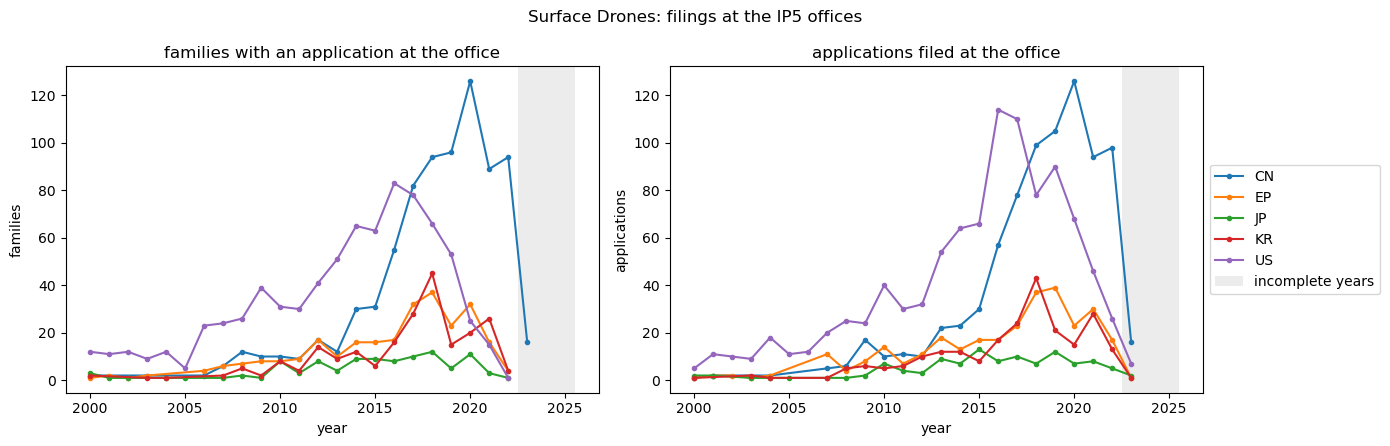

In [39]:
fig, axes = side_by_side(f"{SECTOR_NAME}: filings at the IP5 offices", sharex=True)
for ax, level in zip(axes, LEVELS):
    data = offices.query("level == @level and office in @IP5_OFFICES")
    for office, g in data.groupby("office"):
        ax.plot(g["year"], g["n"], marker="o", ms=3, label=office)
    shade_truncated(ax)
    title = ("families with an application at the office" if level == "family"
             else "applications filed at the office")
    ax.set(title=title, xlabel="year", ylabel=UNIT_LABEL[level])
axes[-1].legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

##  Applicant and inventor countries (fractional counts)

**Applicant country**: where the owners of the technology are (which firms and countries control it).

**Inventor country**: where the research is carried out.

A gap between the two (e.g. inventors in one country, applicants in another) may point to foreign R&D centres or acquisitions. Each column sums to 100%.

In [40]:
countries = pd.concat(
    [fractional_by_country(s, role) for s in SECTOR_SCOPES for role in ("applicant", "inventor")],
    ignore_index=True,
)

country_counts = complete_years(countries).pivot_table(index="ctry", columns=["level", "role"], values="n_frac",
                                                       aggfunc="sum", fill_value=0)
country_counts = country_counts[[(lvl, role) for lvl in LEVELS for role in ("applicant", "inventor")]]
top_countries = country_counts[("family", "applicant")].nlargest(TOP_N).index
country_counts = country_counts.groupby(country_counts.index.where(country_counts.index.isin(top_countries), "Other")).sum()
pct_format(share_table(country_counts))

##PS: watch out for missing values!

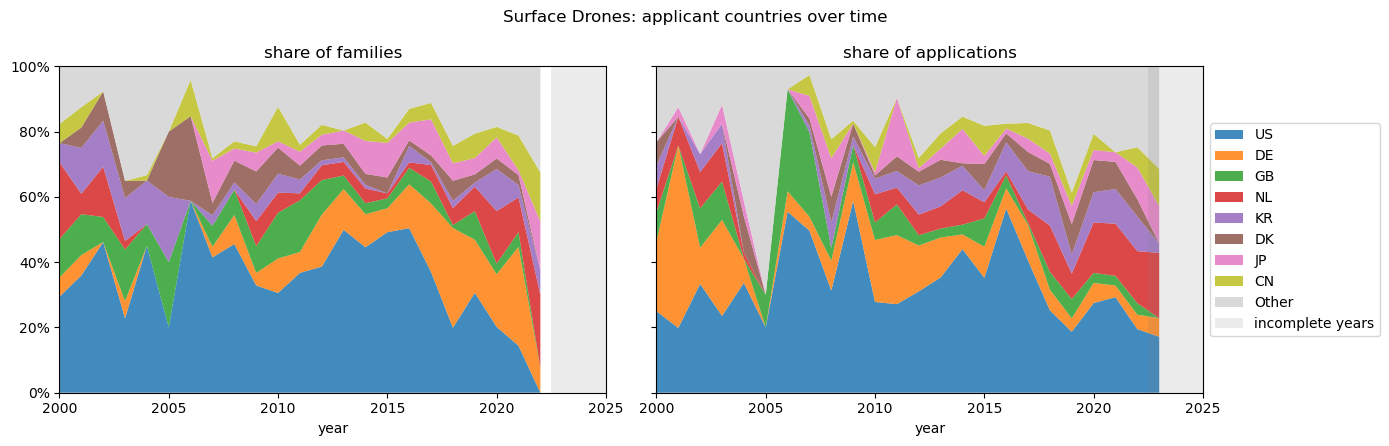

In [41]:
ig, axes = side_by_side(f"{SECTOR_NAME}: applicant countries over time", sharey=True)
for ax, level in zip(axes, LEVELS):
    data = countries.query("role == 'applicant' and level == @level")
    stack_100(ax, share_over_time(pool_other(data, "ctry"), "ctry"), f"share of {UNIT_LABEL[level]}")
axes[-1].legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()
